# Farm Image Counting — baseline

For each farm photo, predict a **density map** of the chickens: a 45×80 grid whose cells hold the (fractional) number of chickens in that part of the image. The sum of the grid is the chicken count.

This notebook runs end to end: **load data → train a small CNN → predict test → write `submission.csv` and `submission.zip`**.

Method: a small fully convolutional network trained from scratch (no pretrained weights) on images resized to 180×320. It outputs one value per cell of the 45×80 grid and is trained with a mean-squared-error loss against the density maps in `train.csv`.

## 1. Load data

data dir: /kaggle/input/datasets/tranphuocsang/farm-image-counting-olpai | device: cuda
train (100, 3) | test (200, 2)
count per image: 15 - 59 | map shape (45, 80)


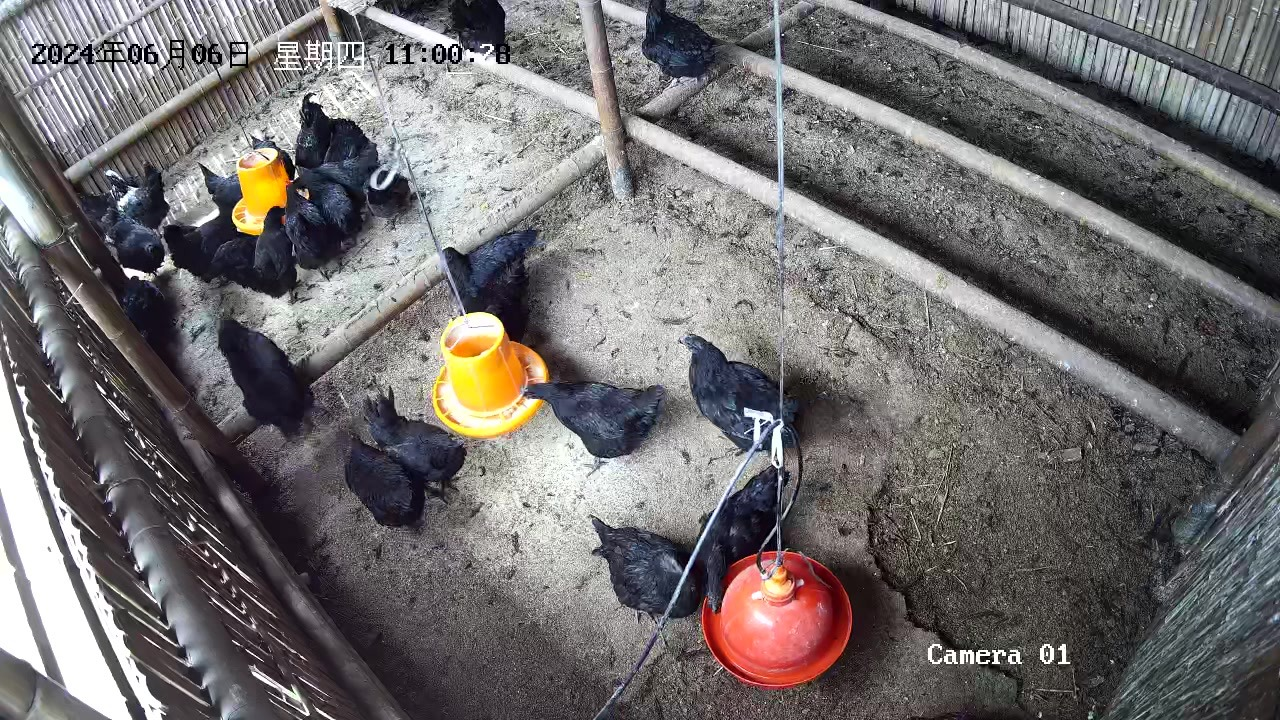

In [7]:
import glob, os, zipfile
import numpy as np, pandas as pd, torch, torch.nn as nn
from PIL import Image

torch.manual_seed(0); np.random.seed(0)
D = os.path.dirname(glob.glob("/kaggle/input/**/train.csv", recursive=True)[0])
train = pd.read_csv(f"{D}/train.csv")
sample = pd.read_csv(f"{D}/sample_submission.csv")
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("data dir:", D, "| device:", dev)
print("train", train.shape, "| test", sample.shape)

def parse(s):
    return np.array(s.split(), dtype=np.float32).reshape(45, 80)

Y = np.stack([parse(s) for s in train["density"]])      # (100, 45, 80): chickens per cell
print("count per image:", train["count"].min(), "-", train["count"].max(), "| map shape", Y.shape[1:])
Image.open(f"{D}/train/{train['id'][0]}.jpg")

## 2. Load the images
Each image is resized to 180×320 and scaled to [0, 1].

In [15]:
def load_all(folder, ids):
    arr = [np.asarray(Image.open(f"{D}/{folder}/{i}.jpg").convert("RGB").resize((320, 180)), dtype=np.float32) / 255.0
           for i in ids]
    return torch.tensor(np.stack(arr)).permute(0, 3, 1, 2)

X_train = load_all("train", train["id"])
X_test = load_all("test", sample["id"])
Y_train = torch.tensor(Y)
print(X_train.shape, X_test.shape)

torch.Size([100, 3, 180, 320]) torch.Size([200, 3, 180, 320])


## 3. Model and training
Five conv layers; two max-pools bring 180×320 down to the 45×80 output grid. Densities are multiplied by 100 so that the loss is on a convenient scale.

In [21]:

def augment_batch(images, targets):
    # images: (B, 3, 180, 320)
    # targets: (B, 45, 80)
    images = images.clone()
    targets = targets.clone()

    # Lật ngang ảnh và nhãn tương ứng với xác suất 50%.
    flip = torch.rand(images.size(0), device=images.device) < 0.5
    images[flip] = images[flip].flip(-1)
    targets[flip] = targets[flip].flip(-1)

    # Mỗi ảnh có hệ số riêng trong khoảng [0.9, 1.1].
    def factor():
        return torch.empty(
            images.size(0), 1, 1, 1,
            device=images.device,
            dtype=images.dtype,
        ).uniform_(0.9, 1.1)

    # Độ sáng.
    images = (images * factor()).clamp(0, 1)

    weights = images.new_tensor(
        [0.2989, 0.5870, 0.1140]
    ).view(1, 3, 1, 1)

    # Độ tương phản.
    gray = (images * weights).sum(dim=1, keepdim=True)
    mean = gray.mean(dim=(2, 3), keepdim=True)
    images = ((images - mean) * factor() + mean).clamp(0, 1)

    # Độ bão hòa màu.
    gray = (images * weights).sum(dim=1, keepdim=True)
    images = ((images - gray) * factor() + gray).clamp(0, 1)

    return images, targets
    
    
SCALE = 100.0

def block(i, o, pool):
    layers = [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU()]
    return nn.Sequential(*layers, nn.MaxPool2d(2)) if pool else nn.Sequential(*layers)

net = nn.Sequential(block(3, 16, True), block(16, 32, True), block(32, 64, False),
                    block(64, 64, False), nn.Conv2d(64, 1, 1)).to(dev)

epochs, bs, lr = 100, 8, 5e-3
opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-5)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * ((len(X_train) + bs - 1) // bs))

for epoch in range(epochs):
    net.train()
    perm = torch.randperm(len(X_train))
    total = 0.0
    for i in range(0, len(X_train), bs):
        idx = perm[i:i + bs]
        images, targets = augment_batch(
            X_train[idx].to(dev),
            Y_train[idx].to(dev),
        )
        
        pred = net(images).squeeze(1)
        loss = ((pred - targets * SCALE) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        total += loss.item() * len(idx)
    if epoch % 5 == 4:
        print(f"epoch {epoch + 1}: train loss {total / len(X_train):.4f}")

epoch 5: train loss 2.1225
epoch 10: train loss 1.7642
epoch 15: train loss 1.6087
epoch 20: train loss 1.8613
epoch 25: train loss 1.3473
epoch 30: train loss 1.1774
epoch 35: train loss 1.1166
epoch 40: train loss 1.0754
epoch 45: train loss 1.0352
epoch 50: train loss 0.9014
epoch 55: train loss 0.8543
epoch 60: train loss 0.8166
epoch 65: train loss 0.8126
epoch 70: train loss 0.7643
epoch 75: train loss 0.7552
epoch 80: train loss 0.7055
epoch 85: train loss 0.6948
epoch 90: train loss 0.6782
epoch 95: train loss 0.6435
epoch 100: train loss 0.6659


## 4. Predict the test images and write the submission
Each row holds the 45×80 map flattened row by row as 3600 space-separated numbers.

In [22]:
net.eval()
with torch.no_grad():
    maps = torch.cat([net(X_test[i:i + 16].to(dev)).squeeze(1).cpu() for i in range(0, len(X_test), 16)])
maps = (maps.clamp(min=0) / SCALE).numpy()               # (200, 45, 80), non-negative

submission = pd.DataFrame({"id": sample["id"], "density": [" ".join(f"{v:.6g}" for v in m.ravel()) for m in maps]})
assert list(submission.columns) == ["id", "density"] and len(submission) == len(sample)
print("predicted counts:", np.round(maps.sum(axis=(1, 2))[:8], 1))

submission.to_csv("submission.csv", index=False)
with zipfile.ZipFile("submission.zip", "w", zipfile.ZIP_DEFLATED) as z:
    z.write("submission.csv")
print(submission.shape, "->", "submission.csv, submission.zip")

predicted counts: [20.9 19.4 34.4 16.8 16.8 17.6 19.5 21.7]
(200, 2) -> submission.csv, submission.zip
